# Notebook 11 – Machine Learning Model Comparison for Dengue Case Forecasting

## Objective

The objective of this notebook is to compare different machine learning algorithms for forecasting dengue case counts in the next reporting period across 25 districts in Sri Lanka.

The comparison will use the same forecasting target, baseline predictors, and chronological training, validation, and testing partitions to ensure a fair evaluation.

## Algorithms

1. Linear Regression
2. Random Forest Regressor
3. HistGradientBoostingRegressor
4. XGBoost Regressor

## Evaluation Metrics

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)

## Experimental Approach

Models will be trained using historical training data, compared using validation data, and the selected model will be evaluated using the untouched test dataset.

The existing HistGradientBoostingRegressor model from Notebook 06 will serve as the benchmark.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib
import json
import time

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from pathlib import Path
import pandas as pd

# Project directories
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "dengue_weather_weekly_25_districts.csv"
)

# Load dataset
df = pd.read_csv(DATA_PATH)

# Convert date columns
df["week_start"] = pd.to_datetime(df["week_start"])
df["week_end"] = pd.to_datetime(df["week_end"])

# Sort chronologically by district
df = df.sort_values(
    ["district_key", "week_start"]
).reset_index(drop=True)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Number of districts:", df["district_key"].nunique())
print("Start date:", df["week_start"].min())
print("End date:", df["week_start"].max())

df.head()

Dataset loaded successfully.
Dataset shape: (24775, 27)
Number of districts: 25
Start date: 2006-12-23 00:00:00
End date: 2025-12-13 00:00:00


,district_key,week_start,week_end,dengue_cases,reporting_period_days,source_reporting_rows,source_areas,weather_days_observed,weather_days_expected,weather_days_complete,...,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,cloud_cover_mean,wind_direction_10m_dominant
0,ampara,2006-12-23,2006-12-29,0,7,2,Ampara | Kalmune,7,7,True,...,27.528571,23.571429,79.857143,87.285714,70.571429,21.471429,15.685714,21.085714,89.142857,8.574025
1,ampara,2006-12-30,2007-01-05,0,7,2,Ampara | Kalmune,7,7,True,...,28.042857,21.385714,71.142857,82.428571,57.000000,18.885714,14.485714,19.614286,59.428571,358.285579
2,ampara,2007-01-06,2007-01-12,0,7,2,Ampara | Kalmune,7,7,True,...,26.957143,23.271429,86.285714,92.285714,78.714286,22.285714,14.842857,18.828571,78.285714,20.694632
3,ampara,2007-01-13,2007-01-19,0,7,2,Ampara | Kalmune,7,7,True,...,27.728571,23.571429,83.142857,89.714286,74.571429,22.357143,17.114286,23.000000,77.857143,11.275426
4,ampara,2007-01-20,2007-01-26,0,7,2,Ampara | Kalmune,7,7,True,...,27.814286,22.742857,76.714286,85.142857,66.142857,20.600000,15.514286,20.385714,71.142857,7.286656


In [3]:
# Create a copy for forecasting feature engineering

forecast_df = df.copy()

# 1. Current-period dengue cases
forecast_df["dengue_current_period"] = (
    forecast_df["dengue_cases"]
)

# 2. Historical dengue lag features
lag_periods = [1, 2, 3, 4, 51, 52]

for lag in lag_periods:
    forecast_df[f"dengue_lag_{lag}"] = (
        forecast_df.groupby("district_key")["dengue_cases"]
        .shift(lag)
    )

# 3. Four-period rolling mean
forecast_df["dengue_rolling_mean_4"] = (
    forecast_df.groupby("district_key")["dengue_cases"]
    .transform(
        lambda s: s.rolling(
            window=4,
            min_periods=2
        ).mean()
    )
)

# 4. Calendar features
week_of_year = (
    forecast_df["week_start"]
    .dt.isocalendar()
    .week.astype(int)
)

forecast_df["month"] = forecast_df["week_start"].dt.month

forecast_df["week_sin"] = np.sin(
    2 * np.pi * week_of_year / 52.1775
)

forecast_df["week_cos"] = np.cos(
    2 * np.pi * week_of_year / 52.1775
)

print("Forecasting features created successfully.")
print("Dataset shape:", forecast_df.shape)

Forecasting features created successfully.
Dataset shape: (24775, 38)


In [4]:
base_features = [
    "district_key",
    "dengue_current_period",
    "dengue_lag_1",
    "dengue_lag_2",
    "dengue_lag_3",
    "dengue_lag_4",
    "dengue_lag_51",
    "dengue_lag_52",
    "dengue_rolling_mean_4",
    "month",
    "week_sin",
    "week_cos"
]

print("Number of predictors:", len(base_features))
print(base_features)

Number of predictors: 12
['district_key', 'dengue_current_period', 'dengue_lag_1', 'dengue_lag_2', 'dengue_lag_3', 'dengue_lag_4', 'dengue_lag_51', 'dengue_lag_52', 'dengue_rolling_mean_4', 'month', 'week_sin', 'week_cos']


In [5]:
print("Target columns available:")

print("target_next_period:",
      "target_next_period" in forecast_df.columns)

print("target_week_start:",
      "target_week_start" in forecast_df.columns)

print("\nLast available columns:")
print(forecast_df.columns.tolist()[-10:])

Target columns available:
target_next_period: False
target_week_start: False

Last available columns:
['dengue_lag_1', 'dengue_lag_2', 'dengue_lag_3', 'dengue_lag_4', 'dengue_lag_51', 'dengue_lag_52', 'dengue_rolling_mean_4', 'month', 'week_sin', 'week_cos']


In [6]:
# Sort data chronologically within each district
forecast_df = forecast_df.sort_values(
    ["district_key", "week_start"]
).reset_index(drop=True)

# Create target columns
forecast_df["target_next_period"] = (
    forecast_df.groupby("district_key")["dengue_cases"].shift(-1)
)

forecast_df["target_week_start"] = (
    forecast_df.groupby("district_key")["week_start"].shift(-1)
)

# Verify
print("Target columns created:")
print(forecast_df[
    ["district_key", "week_start",
     "target_next_period", "target_week_start"]
].head())

print("\nTarget columns exist:",
      "target_next_period" in forecast_df.columns and
      "target_week_start" in forecast_df.columns)

Target columns created:
  district_key week_start  target_next_period target_week_start
0       ampara 2006-12-23                 0.0        2006-12-30
1       ampara 2006-12-30                 0.0        2007-01-06
2       ampara 2007-01-06                 0.0        2007-01-13
3       ampara 2007-01-13                 0.0        2007-01-20
4       ampara 2007-01-20                 0.0        2007-01-27

Target columns exist: True


In [7]:
forecast_final = forecast_df.dropna(
    subset=["target_next_period", "target_week_start"]
).copy()

forecast_final = forecast_final.sort_values(
    ["target_week_start", "district_key"]
).reset_index(drop=True)

print("Final dataset shape:", forecast_final.shape)
print("Number of districts:", forecast_final["district_key"].nunique())
print("Missing targets:", forecast_final["target_next_period"].isna().sum())
print("Duplicate district-target dates:",
      forecast_final.duplicated(
          ["district_key", "target_week_start"]
      ).sum())

Final dataset shape: (24750, 40)
Number of districts: 25
Missing targets: 0
Duplicate district-target dates: 0


In [8]:
# Chronological split using target reporting dates

train_mask = (
    forecast_final["target_week_start"]
    <= pd.Timestamp("2020-04-04")
)

valid_mask = (
    (forecast_final["target_week_start"] >= pd.Timestamp("2020-04-11")) &
    (forecast_final["target_week_start"] <= pd.Timestamp("2023-02-04"))
)

test_mask = (
    (forecast_final["target_week_start"] >= pd.Timestamp("2023-02-11")) &
    (forecast_final["target_week_start"] <= pd.Timestamp("2025-12-13"))
)

train = forecast_final.loc[train_mask].copy()
valid = forecast_final.loc[valid_mask].copy()
test = forecast_final.loc[test_mask].copy()

print("Training rows:", len(train))
print("Validation rows:", len(valid))
print("Testing rows:", len(test))

print("\nTraining date range:")
print(train["target_week_start"].min(), "to",
      train["target_week_start"].max())

print("\nValidation date range:")
print(valid["target_week_start"].min(), "to",
      valid["target_week_start"].max())

print("\nTesting date range:")
print(test["target_week_start"].min(), "to",
      test["target_week_start"].max())

Training rows: 17325
Validation rows: 3700
Testing rows: 3725

Training date range:
2006-12-30 00:00:00 to 2020-04-04 00:00:00

Validation date range:
2020-04-11 00:00:00 to 2023-02-04 00:00:00

Testing date range:
2023-02-11 00:00:00 to 2025-12-13 00:00:00


In [9]:
# Define the 12 baseline predictors

base_features = [
    "district_key",
    "dengue_current_period",
    "dengue_lag_1",
    "dengue_lag_2",
    "dengue_lag_3",
    "dengue_lag_4",
    "dengue_lag_51",
    "dengue_lag_52",
    "dengue_rolling_mean_4",
    "month",
    "week_sin",
    "week_cos"
]

target = "target_next_period"

# Separate predictors and targets

X_train = train[base_features].copy()
y_train = train[target].copy()

X_valid = valid[base_features].copy()
y_valid = valid[target].copy()

X_test = test[base_features].copy()
y_test = test[target].copy()

print("Training predictors:", X_train.shape)
print("Validation predictors:", X_valid.shape)
print("Testing predictors:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Validation target:", y_valid.shape)
print("Testing target:", y_test.shape)

Training predictors: (17325, 12)
Validation predictors: (3700, 12)
Testing predictors: (3725, 12)

Training target: (17325,)
Validation target: (3700,)
Testing target: (3725,)


In [10]:
# Define categorical and numerical features

categorical_features = ["district_key"]

numeric_features = [
    feature for feature in base_features
    if feature not in categorical_features
]

# Numerical preprocessing

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Preprocessing pipeline created successfully.
Numerical features: 11
Categorical features: 1


In [11]:
# Create Linear Regression pipeline

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

print("Linear Regression pipeline created.")

Linear Regression pipeline created.


In [12]:
import time

start_time = time.time()

linear_model.fit(X_train, y_train)

linear_training_time = time.time() - start_time

print("Linear Regression trained successfully.")
print("Training time:", round(linear_training_time, 2), "seconds")

Linear Regression trained successfully.
Training time: 0.27 seconds


In [13]:
linear_valid_predictions = linear_model.predict(X_valid)

print("Validation predictions generated.")

print("First 10 actual values:")
print(y_valid.head(10).values)

print("\nFirst 10 predicted values:")
print(np.round(linear_valid_predictions[:10], 2))

Validation predictions generated.
First 10 actual values:
[ 7.  0.  1. 23.  8.  1.  2.  4.  4.  8.]

First 10 predicted values:
[11.17  2.77  2.83 22.36 17.03  3.34 15.11  1.87 12.19 13.9 ]


In [14]:
linear_mae = mean_absolute_error(
    y_valid,
    linear_valid_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_valid, linear_valid_predictions)
)

linear_r2 = r2_score(
    y_valid,
    linear_valid_predictions
)

print("LINEAR REGRESSION - VALIDATION RESULTS")
print("--------------------------------------")
print("MAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R2:", round(linear_r2, 4))

LINEAR REGRESSION - VALIDATION RESULTS
--------------------------------------
MAE: 9.0003
RMSE: 18.9857
R2: 0.6247


In [15]:
# Store Linear Regression results

model_results = []

model_results.append({
    "Model": "Linear Regression",
    "Validation_MAE": linear_mae,
    "Validation_RMSE": linear_rmse,
    "Validation_R2": linear_r2,
    "Training_Time_Seconds": linear_training_time
})

print(pd.DataFrame(model_results))

               Model  Validation_MAE  Validation_RMSE  Validation_R2  \
0  Linear Regression        9.000268        18.985684       0.624675   

   Training_Time_Seconds  
0               0.274094  


In [16]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [17]:
start_time = time.time()

random_forest_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

print("Random Forest trained successfully.")
print("Training time:", round(rf_training_time, 2), "seconds")

Random Forest trained successfully.
Training time: 4.99 seconds


In [18]:
rf_valid_predictions = random_forest_model.predict(X_valid)

rf_mae = mean_absolute_error(
    y_valid, rf_valid_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_valid, rf_valid_predictions)
)

rf_r2 = r2_score(
    y_valid, rf_valid_predictions
)

print("RANDOM FOREST - VALIDATION RESULTS")
print("----------------------------------")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2:", round(rf_r2, 4))

RANDOM FOREST - VALIDATION RESULTS
----------------------------------
MAE: 9.16
RMSE: 20.1172
R2: 0.5786


In [19]:
model_results.append({
    "Model": "Random Forest",
    "Validation_MAE": rf_mae,
    "Validation_RMSE": rf_rmse,
    "Validation_R2": rf_r2,
    "Training_Time_Seconds": rf_training_time
})

print(
    pd.DataFrame(model_results)
    .sort_values("Validation_RMSE")
)

               Model  Validation_MAE  Validation_RMSE  Validation_R2  \
0  Linear Regression        9.000268        18.985684       0.624675   
1      Random Forest        9.159959        20.117233       0.578603   

   Training_Time_Seconds  
0               0.274094  
1               4.991949  


In [26]:
# MODEL 3: HISTOGRAM GRADIENT BOOSTING
# Reproduce Notebook 06 configuration

hgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    ))
])

start_time = time.time()

hgb_model.fit(X_train, y_train)

hgb_training_time = time.time() - start_time

hgb_valid_predictions = np.maximum(
    0,
    hgb_model.predict(X_valid)
)

hgb_mae = mean_absolute_error(
    y_valid, hgb_valid_predictions
)

hgb_rmse = np.sqrt(
    mean_squared_error(y_valid, hgb_valid_predictions)
)

hgb_r2 = r2_score(
    y_valid, hgb_valid_predictions
)

print("HIST GRADIENT BOOSTING - VALIDATION RESULTS")
print("-------------------------------------------")
print("MAE:", round(hgb_mae, 4))
print("RMSE:", round(hgb_rmse, 4))
print("R2:", round(hgb_r2, 4))
print("Training time:", round(hgb_training_time, 4), "seconds")

HIST GRADIENT BOOSTING - VALIDATION RESULTS
-------------------------------------------
MAE: 8.6461
RMSE: 18.4345
R2: 0.6461
Training time: 0.2666 seconds


In [27]:
# UPDATE HISTGRADIENTBOOSTING RESULTS

hgb_index = next(
    i for i, row in enumerate(model_results)
    if row["Model"] == "HistGradientBoosting"
)

model_results[hgb_index].update({
    "Validation_MAE": hgb_mae,
    "Validation_RMSE": hgb_rmse,
    "Validation_R2": hgb_r2,
    "Training_Time_Seconds": hgb_training_time
})

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    "Validation_RMSE"
).reset_index(drop=True)

display(results_df)

,Model,Validation_MAE,Validation_RMSE,Validation_R2,Training_Time_Seconds
0,HistGradientBoosting,8.646060,18.434544,0.646150,0.266634
1,Linear Regression,9.000268,18.985684,0.624675,0.274094
2,XGBoost,8.919708,19.151828,0.618078,0.514705
3,Random Forest,9.159959,20.117233,0.578603,4.991949


In [23]:
try:
    import xgboost
    from xgboost import XGBRegressor

    print("XGBoost is installed.")
    print("Version:", xgboost.__version__)

except ImportError:
    print("XGBoost is not installed.")

XGBoost is installed.
Version: 3.2.0


In [24]:
# MODEL 4: XGBOOST REGRESSOR

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

start_time = time.time()

xgb_model.fit(X_train, y_train)

xgb_training_time = time.time() - start_time

xgb_valid_predictions = xgb_model.predict(X_valid)

xgb_mae = mean_absolute_error(
    y_valid, xgb_valid_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(y_valid, xgb_valid_predictions)
)

xgb_r2 = r2_score(
    y_valid, xgb_valid_predictions
)

print("XGBOOST - VALIDATION RESULTS")
print("----------------------------")
print("MAE:", round(xgb_mae, 4))
print("RMSE:", round(xgb_rmse, 4))
print("R2:", round(xgb_r2, 4))
print("Training time:", round(xgb_training_time, 4), "seconds")

model_results.append({
    "Model": "XGBoost",
    "Validation_MAE": xgb_mae,
    "Validation_RMSE": xgb_rmse,
    "Validation_R2": xgb_r2,
    "Training_Time_Seconds": xgb_training_time
})

results_df = pd.DataFrame(model_results)

print("\nUPDATED MODEL COMPARISON")
display(
    results_df.sort_values(
        by="Validation_RMSE",
        ascending=True
    ).reset_index(drop=True)
)

XGBOOST - VALIDATION RESULTS
----------------------------
MAE: 8.9197
RMSE: 19.1518
R2: 0.6181
Training time: 0.5147 seconds

UPDATED MODEL COMPARISON


,Model,Validation_MAE,Validation_RMSE,Validation_R2,Training_Time_Seconds
0,HistGradientBoosting,8.658672,18.520631,0.642837,2.778633
1,Linear Regression,9.000268,18.985684,0.624675,0.274094
2,XGBoost,8.919708,19.151828,0.618078,0.514705
3,Random Forest,9.159959,20.117233,0.578603,4.991949


In [ ]:
results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by="Validation_RMSE",
    ascending=True
).reset_index(drop=True)

results_path = (
    PROJECT_ROOT
    / "outputs"
    / "model_comparison"
    / "machine_learning_validation_comparison.csv"
)

results_df.to_csv(results_path, index=False)

print("Updated comparison saved:")
print(results_path)

display(results_df)

Validation comparison saved successfully:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\model_comparison\machine_learning_validation_comparison.csv


,Model,Validation_MAE,Validation_RMSE,Validation_R2,Training_Time_Seconds
0,HistGradientBoosting,8.658672,18.520631,0.642837,2.778633
1,Linear Regression,9.000268,18.985684,0.624675,0.274094
2,XGBoost,8.919708,19.151828,0.618078,0.514705
3,Random Forest,9.159959,20.117233,0.578603,4.991949


In [28]:
# SECTION 12: HISTGRADIENTBOOSTING HYPERPARAMETER TUNING

from sklearn.model_selection import ParameterGrid

print("Hyperparameter tuning setup completed.")

Hyperparameter tuning setup completed.


In [29]:
# DEFINE HYPERPARAMETER SEARCH SPACE

param_grid = {
    "max_iter": [100, 200, 300],
    "learning_rate": [0.05, 0.08, 0.1],
    "max_leaf_nodes": [15, 20, 31],
    "l2_regularization": [0.0, 1.0]
}

parameter_combinations = list(ParameterGrid(param_grid))

print("Total parameter combinations:",
      len(parameter_combinations))

Total parameter combinations: 54


In [30]:
# RUN HISTGRADIENTBOOSTING HYPERPARAMETER TUNING

tuning_results = []

for i, params in enumerate(parameter_combinations, start=1):

    print(f"Testing configuration {i}/{len(parameter_combinations)}")

    tuning_model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", HistGradientBoostingRegressor(
            **params,
            random_state=42
        ))
    ])

    start_time = time.time()

    tuning_model.fit(X_train, y_train)

    training_time = time.time() - start_time

    valid_predictions = np.maximum(
        0,
        tuning_model.predict(X_valid)
    )

    mae = mean_absolute_error(
        y_valid, valid_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_valid, valid_predictions)
    )

    r2 = r2_score(
        y_valid, valid_predictions
    )

    tuning_results.append({
        "max_iter": params["max_iter"],
        "learning_rate": params["learning_rate"],
        "max_leaf_nodes": params["max_leaf_nodes"],
        "l2_regularization": params["l2_regularization"],
        "Validation_MAE": mae,
        "Validation_RMSE": rmse,
        "Validation_R2": r2,
        "Training_Time_Seconds": training_time
    })

print("\nHyperparameter tuning completed.")

Testing configuration 1/54
Testing configuration 2/54
Testing configuration 3/54
Testing configuration 4/54
Testing configuration 5/54
Testing configuration 6/54
Testing configuration 7/54
Testing configuration 8/54
Testing configuration 9/54
Testing configuration 10/54
Testing configuration 11/54
Testing configuration 12/54
Testing configuration 13/54
Testing configuration 14/54
Testing configuration 15/54
Testing configuration 16/54
Testing configuration 17/54
Testing configuration 18/54
Testing configuration 19/54
Testing configuration 20/54
Testing configuration 21/54
Testing configuration 22/54
Testing configuration 23/54
Testing configuration 24/54
Testing configuration 25/54
Testing configuration 26/54
Testing configuration 27/54
Testing configuration 28/54
Testing configuration 29/54
Testing configuration 30/54
Testing configuration 31/54
Testing configuration 32/54
Testing configuration 33/54
Testing configuration 34/54
Testing configuration 35/54
Testing configuration 36/54
T

In [31]:
# DISPLAY HYPERPARAMETER TUNING RESULTS

tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    by="Validation_RMSE",
    ascending=True
).reset_index(drop=True)

display(tuning_results_df.head(10))

,max_iter,learning_rate,max_leaf_nodes,l2_regularization,Validation_MAE,Validation_RMSE,Validation_R2,Training_Time_Seconds
0,100,0.05,15,1.0,8.697864,18.181872,0.655783,0.223522
1,200,0.05,15,1.0,8.697864,18.181872,0.655783,0.222922
2,300,0.05,15,1.0,8.697864,18.181872,0.655783,0.224927
3,100,0.08,15,1.0,8.576438,18.271369,0.652386,0.201972
4,300,0.08,15,1.0,8.576438,18.271369,0.652386,0.226298
5,200,0.08,15,1.0,8.576438,18.271369,0.652386,0.221764
6,100,0.05,20,0.0,8.642348,18.300195,0.651289,0.359147
7,200,0.05,20,0.0,8.642348,18.300195,0.651289,0.296656
8,300,0.05,20,0.0,8.642348,18.300195,0.651289,0.336298
9,300,0.08,15,0.0,8.664219,18.314781,0.650733,0.220217


In [32]:
# IDENTIFY BEST HISTGRADIENTBOOSTING CONFIGURATION

best_result = tuning_results_df.iloc[0]

best_params = {
    "max_iter": int(best_result["max_iter"]),
    "learning_rate": float(best_result["learning_rate"]),
    "max_leaf_nodes": int(best_result["max_leaf_nodes"]),
    "l2_regularization": float(best_result["l2_regularization"])
}

print("BEST HISTGRADIENTBOOSTING PARAMETERS")
print("------------------------------------")

for parameter, value in best_params.items():
    print(f"{parameter}: {value}")

print("\nBEST VALIDATION RESULTS")
print("MAE:", round(best_result["Validation_MAE"], 4))
print("RMSE:", round(best_result["Validation_RMSE"], 4))
print("R2:", round(best_result["Validation_R2"], 4))

BEST HISTGRADIENTBOOSTING PARAMETERS
------------------------------------
max_iter: 100
learning_rate: 0.05
max_leaf_nodes: 15
l2_regularization: 1.0

BEST VALIDATION RESULTS
MAE: 8.6979
RMSE: 18.1819
R2: 0.6558


In [33]:
# SAVE HYPERPARAMETER TUNING RESULTS

TUNING_OUTPUT_DIR = (
    PROJECT_ROOT / "outputs" / "model_comparison"
)

TUNING_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

tuning_results_path = (
    TUNING_OUTPUT_DIR /
    "histgradientboosting_hyperparameter_tuning.csv"
)

tuning_results_df.to_csv(
    tuning_results_path,
    index=False
)

best_params_path = (
    TUNING_OUTPUT_DIR /
    "best_histgradientboosting_parameters.json"
)

with open(best_params_path, "w") as f:
    json.dump(best_params, f, indent=4)

print("Tuning results saved successfully.")
print(tuning_results_path)
print(best_params_path)

Tuning results saved successfully.
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\model_comparison\histgradientboosting_hyperparameter_tuning.csv
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\model_comparison\best_histgradientboosting_parameters.json


In [34]:
# CELL 12.7: SAVE BEST MODEL VALIDATION METRICS

best_model_summary = pd.DataFrame([{
    "Model": "Tuned HistGradientBoosting",
    "max_iter": best_params["max_iter"],
    "learning_rate": best_params["learning_rate"],
    "max_leaf_nodes": best_params["max_leaf_nodes"],
    "l2_regularization": best_params["l2_regularization"],
    "Validation_MAE": best_result["Validation_MAE"],
    "Validation_RMSE": best_result["Validation_RMSE"],
    "Validation_R2": best_result["Validation_R2"]
}])

summary_path = (
    PROJECT_ROOT
    / "outputs"
    / "model_comparison"
    / "best_histgradientboosting_validation_metrics.csv"
)

best_model_summary.to_csv(summary_path, index=False)

display(best_model_summary)

print("Best model summary saved:")
print(summary_path)

,Model,max_iter,learning_rate,max_leaf_nodes,l2_regularization,Validation_MAE,Validation_RMSE,Validation_R2
0,Tuned HistGradientBoosting,100,0.05,15,1.0,8.697864,18.181872,0.655783


Best model summary saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\model_comparison\best_histgradientboosting_validation_metrics.csv


In [35]:
# CELL 13.1: COMBINE TRAINING AND VALIDATION DATA

X_train_valid = pd.concat(
    [X_train, X_valid],
    axis=0
).reset_index(drop=True)

y_train_valid = pd.concat(
    [y_train, y_valid],
    axis=0
).reset_index(drop=True)

print("Combined training and validation data")
print("--------------------------------------")
print("X_train_valid shape:", X_train_valid.shape)
print("y_train_valid shape:", y_train_valid.shape)
print("Test data shape:", X_test.shape)

assert len(X_train_valid) == len(y_train_valid)
assert len(X_train_valid) == 21025
assert len(X_test) == 3725

print("\nData preparation completed successfully.")

Combined training and validation data
--------------------------------------
X_train_valid shape: (21025, 12)
y_train_valid shape: (21025,)
Test data shape: (3725, 12)

Data preparation completed successfully.


In [36]:
# CELL 13.2: TRAIN FINAL TUNED HISTGRADIENTBOOSTING MODEL

final_hgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(
        **best_params,
        random_state=42
    ))
])

start_time = time.time()

final_hgb_model.fit(
    X_train_valid,
    y_train_valid
)

final_training_time = time.time() - start_time

print("Final model training completed.")
print("Training time:", round(final_training_time, 4), "seconds")

Final model training completed.
Training time: 0.3478 seconds


In [37]:
# CELL 13.3: FINAL TEST PREDICTIONS

final_test_predictions = np.maximum(
    0,
    final_hgb_model.predict(X_test)
)

final_test_mae = mean_absolute_error(
    y_test,
    final_test_predictions
)

final_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_test_predictions
    )
)

final_test_r2 = r2_score(
    y_test,
    final_test_predictions
)

print("FINAL TUNED MODEL - TEST RESULTS")
print("--------------------------------")
print("MAE:", round(final_test_mae, 4))
print("RMSE:", round(final_test_rmse, 4))
print("R2:", round(final_test_r2, 4))

FINAL TUNED MODEL - TEST RESULTS
--------------------------------
MAE: 12.5643
RMSE: 29.904
R2: 0.8193


In [38]:
# CELL 13.4: SAVE FINAL TEST METRICS

final_test_metrics = pd.DataFrame([{
    "Model": "Tuned HistGradientBoosting",
    "Test_MAE": final_test_mae,
    "Test_RMSE": final_test_rmse,
    "Test_R2": final_test_r2,
    "Training_Time_Seconds": final_training_time
}])

test_metrics_path = (
    PROJECT_ROOT
    / "outputs"
    / "model_comparison"
    / "final_tuned_model_test_metrics.csv"
)

final_test_metrics.to_csv(
    test_metrics_path,
    index=False
)

display(final_test_metrics)

print("Test metrics saved:")
print(test_metrics_path)

,Model,Test_MAE,Test_RMSE,Test_R2,Training_Time_Seconds
0,Tuned HistGradientBoosting,12.564265,29.904042,0.819327,0.347825


Test metrics saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\model_comparison\final_tuned_model_test_metrics.csv


In [39]:
# CELL 13.5: SAVE FINAL TEST PREDICTIONS

final_predictions_df = test[
    ["district_key", "target_week_start", "target_next_period"]
].copy()

final_predictions_df["predicted_dengue_cases"] = (
    final_test_predictions
)

final_predictions_df = final_predictions_df.rename(
    columns={
        "target_next_period": "actual_dengue_cases"
    }
)

predictions_path = (
    PROJECT_ROOT
    / "outputs"
    / "model_comparison"
    / "final_tuned_model_test_predictions.csv"
)

final_predictions_df.to_csv(
    predictions_path,
    index=False
)

print("Test predictions saved:")
print(predictions_path)

display(final_predictions_df.head())

Test predictions saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\model_comparison\final_tuned_model_test_predictions.csv


,district_key,target_week_start,actual_dengue_cases,predicted_dengue_cases
21025,ampara,2023-02-11,55.0,78.108538
21026,anuradhapura,2023-02-11,11.0,10.464106
21027,badulla,2023-02-11,35.0,37.005736
21028,batticaloa,2023-02-11,41.0,49.034992
21029,colombo,2023-02-11,160.0,187.127331


In [40]:
# CELL 13.6: SAVE TUNED MODEL

model_output_dir = (
    PROJECT_ROOT / "outputs" / "model_comparison"
)

model_output_dir.mkdir(parents=True, exist_ok=True)

final_model_path = (
    model_output_dir /
    "riskweave_tuned_histgradientboosting_candidate.joblib"
)

joblib.dump(final_hgb_model, final_model_path)

print("Tuned model saved successfully:")
print(final_model_path)

Tuned model saved successfully:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\model_comparison\riskweave_tuned_histgradientboosting_candidate.joblib


In [41]:
# CELL 14.1: CALCULATE PREDICTION ERRORS

error_df = final_predictions_df.copy()

error_df["prediction_error"] = (
    error_df["predicted_dengue_cases"]
    - error_df["actual_dengue_cases"]
)

error_df["absolute_error"] = (
    error_df["prediction_error"].abs()
)

error_df["squared_error"] = (
    error_df["prediction_error"] ** 2
)

print("Prediction error analysis dataset:")
print("Shape:", error_df.shape)

display(error_df.head())

Prediction error analysis dataset:
Shape: (3725, 7)


,district_key,target_week_start,actual_dengue_cases,predicted_dengue_cases,prediction_error,absolute_error,squared_error
21025,ampara,2023-02-11,55.0,78.108538,23.108538,23.108538,534.004546
21026,anuradhapura,2023-02-11,11.0,10.464106,-0.535894,0.535894,0.287182
21027,badulla,2023-02-11,35.0,37.005736,2.005736,2.005736,4.022975
21028,batticaloa,2023-02-11,41.0,49.034992,8.034992,8.034992,64.561103
21029,colombo,2023-02-11,160.0,187.127331,27.127331,27.127331,735.892077


In [42]:
# CELL 14.2: OVERALL ERROR SUMMARY

error_summary = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error",
        "Root Mean Squared Error",
        "Mean Prediction Error",
        "Maximum Absolute Error"
    ],
    "Value": [
        error_df["absolute_error"].mean(),
        np.sqrt(error_df["squared_error"].mean()),
        error_df["prediction_error"].mean(),
        error_df["absolute_error"].max()
    ]
})

display(error_summary)

,Metric,Value
0,Mean Absolute Error,12.564265
1,Root Mean Squared Error,29.904042
2,Mean Prediction Error,0.385157
3,Maximum Absolute Error,615.613659


In [43]:
# CELL 14.3: DISTRICT-WISE ERROR ANALYSIS

district_error_summary = (
    error_df.groupby("district_key")
    .agg(
        Actual_Mean=("actual_dengue_cases", "mean"),
        Predicted_Mean=("predicted_dengue_cases", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=("squared_error",
              lambda x: np.sqrt(x.mean())),
        Mean_Error=("prediction_error", "mean")
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

display(district_error_summary)

,district_key,Actual_Mean,Predicted_Mean,MAE,RMSE,Mean_Error
4,colombo,235.456376,243.659598,48.264560,73.383896,8.203223
6,gampaha,140.087248,135.987808,28.970885,41.957168,-4.099440
9,kalutara,66.711409,66.167735,26.829070,70.906537,-0.543674
10,kandy,115.785235,111.393958,25.197165,47.339055,-4.391277
8,jaffna,76.489933,71.824714,24.159321,61.401862,-4.665219
22,ratnapura,63.348993,65.596523,18.906212,31.274188,2.247530
13,kurunegala,43.255034,44.461762,12.143900,19.065469,1.206729
11,kegalle,42.617450,43.283177,11.991177,17.623196,0.665727
5,galle,50.852349,49.484999,11.718290,17.025447,-1.367350
21,puttalam,27.308725,28.732234,10.292570,16.140522,1.423510


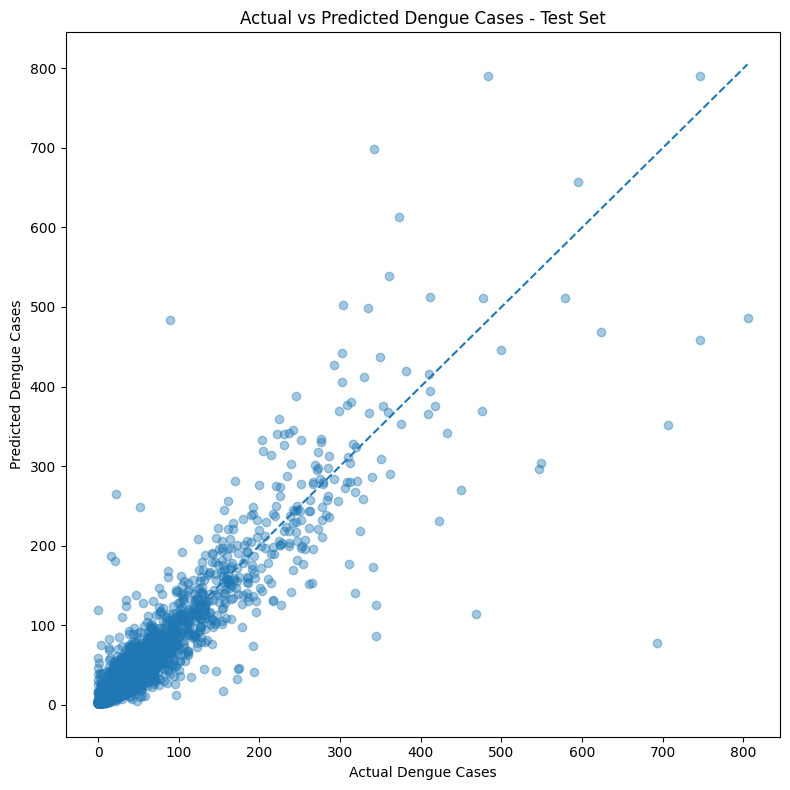

In [44]:
# CELL 14.4: ACTUAL VS PREDICTED

plt.figure(figsize=(8, 8))

plt.scatter(
    error_df["actual_dengue_cases"],
    error_df["predicted_dengue_cases"],
    alpha=0.4
)

max_value = max(
    error_df["actual_dengue_cases"].max(),
    error_df["predicted_dengue_cases"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Dengue Cases")
plt.ylabel("Predicted Dengue Cases")
plt.title("Actual vs Predicted Dengue Cases - Test Set")

plt.tight_layout()
plt.show()

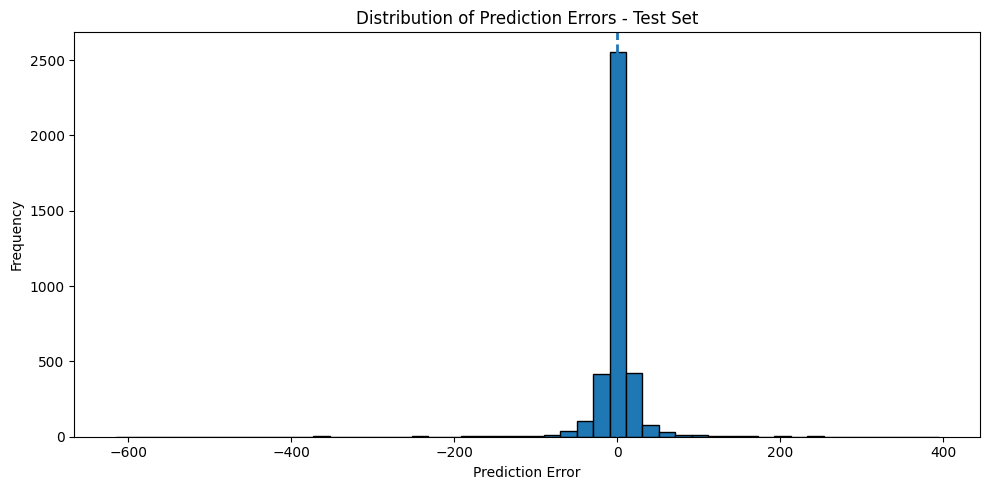

In [45]:
# CELL 15.1: RESIDUAL DISTRIBUTION

plt.figure(figsize=(10, 5))

plt.hist(
    error_df["prediction_error"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors - Test Set")

plt.tight_layout()
plt.show()

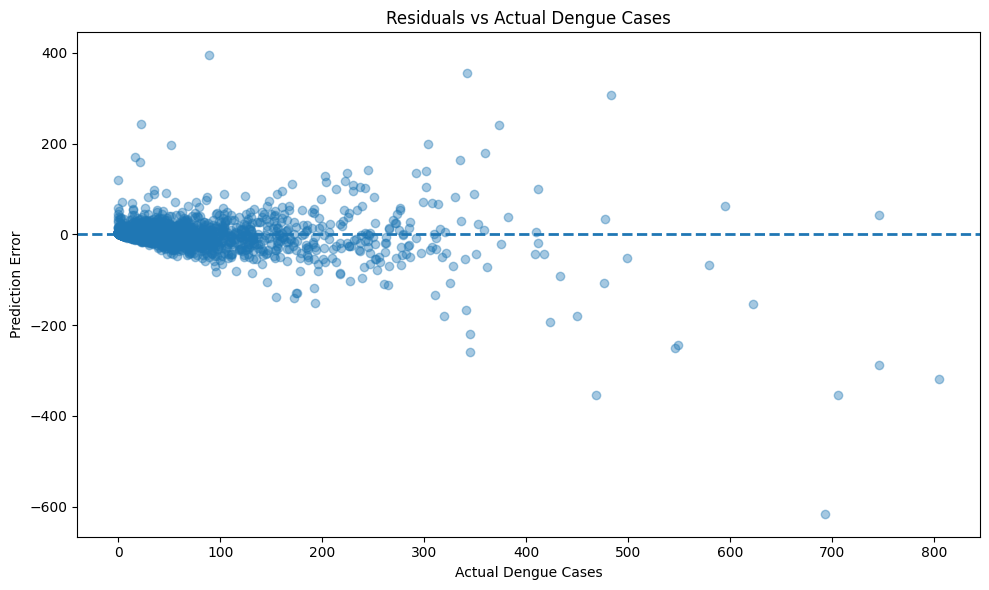

In [46]:
# CELL 15.2: RESIDUALS VS ACTUAL DENGUE CASES

plt.figure(figsize=(10, 6))

plt.scatter(
    error_df["actual_dengue_cases"],
    error_df["prediction_error"],
    alpha=0.4
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual Dengue Cases")
plt.ylabel("Prediction Error")
plt.title("Residuals vs Actual Dengue Cases")

plt.tight_layout()
plt.show()

In [47]:
# CELL 15.3: LARGEST PREDICTION ERRORS

largest_errors = error_df.sort_values(
    by="absolute_error",
    ascending=False
).head(20)

display(
    largest_errors[
        [
            "district_key",
            "target_week_start",
            "actual_dengue_cases",
            "predicted_dengue_cases",
            "prediction_error",
            "absolute_error"
        ]
    ]
)

,district_key,target_week_start,actual_dengue_cases,predicted_dengue_cases,prediction_error,absolute_error
22134,kalutara,2023-12-16,693.0,77.386341,-615.613659,615.613659
22159,kalutara,2023-12-23,89.0,483.821968,394.821968,394.821968
21504,colombo,2023-06-24,342.0,698.782392,356.782392,356.782392
22133,jaffna,2023-12-16,706.0,351.501499,-354.498501,354.498501
22085,kandy,2023-12-02,469.0,114.643398,-354.356602,354.356602
22208,jaffna,2024-01-06,805.0,485.604281,-319.395719,319.395719
22283,jaffna,2024-01-27,483.0,789.773553,306.773553,306.773553
22158,jaffna,2023-12-23,746.0,458.758262,-287.241738,287.241738
21934,kalutara,2023-10-21,345.0,86.532911,-258.467089,258.467089
21404,colombo,2023-05-27,546.0,296.581438,-249.418562,249.418562


In [48]:
# CELL 16.1: CLASSIFY TEST OBSERVATIONS BY ACTUAL CASE LEVEL

error_df["case_level"] = pd.cut(
    error_df["actual_dengue_cases"],
    bins=[-np.inf, 50, 200, np.inf],
    labels=["Low", "Medium", "High"]
)

print("Case-level distribution:")
display(
    error_df["case_level"].value_counts()
    .reindex(["Low", "Medium", "High"])
)

Case-level distribution:


case_level
Low       2818
Medium     753
High       154
Name: count, dtype: int64

In [49]:
# CELL 16.2: PERFORMANCE BY CASE LEVEL

case_level_summary = (
    error_df.groupby("case_level", observed=False)
    .agg(
        Observations=("actual_dengue_cases", "count"),
        Actual_Mean=("actual_dengue_cases", "mean"),
        Predicted_Mean=("predicted_dengue_cases", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=("squared_error", lambda x: np.sqrt(x.mean())),
        Mean_Error=("prediction_error", "mean")
    )
    .reset_index()
)

display(case_level_summary)

,case_level,Observations,Actual_Mean,Predicted_Mean,MAE,RMSE,Mean_Error
0,Low,2818,16.901703,19.593484,6.593727,12.148437,2.691781
1,Medium,753,93.952191,89.309721,21.994499,33.512436,-4.642471
2,High,154,308.532468,291.292546,75.707196,115.924091,-17.239921


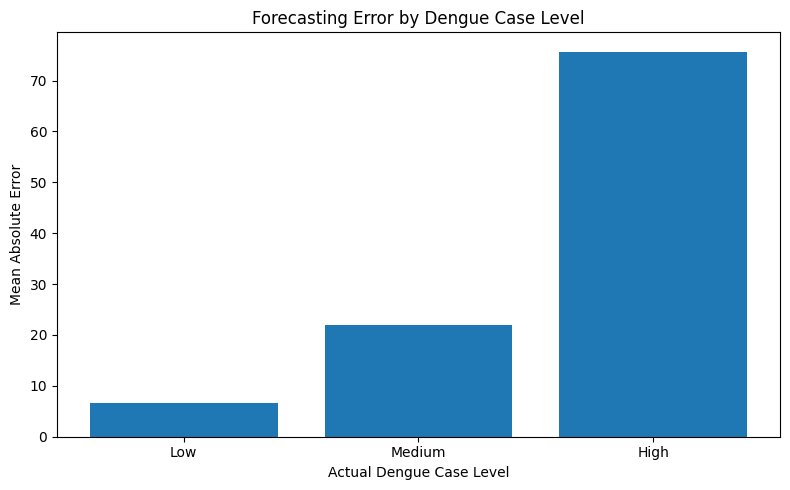

In [50]:
# CELL 16.3: MAE BY DENGUE CASE LEVEL

plt.figure(figsize=(8, 5))

plt.bar(
    case_level_summary["case_level"].astype(str),
    case_level_summary["MAE"]
)

plt.xlabel("Actual Dengue Case Level")
plt.ylabel("Mean Absolute Error")
plt.title("Forecasting Error by Dengue Case Level")

plt.tight_layout()
plt.show()

In [51]:
# CELL 16.4: SAVE CASE-LEVEL PERFORMANCE

case_level_path = (
    PROJECT_ROOT
    / "outputs"
    / "model_comparison"
    / "performance_by_dengue_case_level.csv"
)

case_level_summary.to_csv(
    case_level_path,
    index=False
)

print("Case-level performance saved:")
print(case_level_path)

Case-level performance saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\model_comparison\performance_by_dengue_case_level.csv


In [52]:
# CELL 17.1: EXTRACT TEMPORAL FEATURES

error_df["target_week_start"] = pd.to_datetime(
    error_df["target_week_start"]
)

error_df["target_year"] = (
    error_df["target_week_start"].dt.year
)

error_df["target_month"] = (
    error_df["target_week_start"].dt.month
)

error_df["target_quarter"] = (
    error_df["target_week_start"].dt.quarter
)

print("Temporal features created.")

display(
    error_df[
        [
            "target_week_start",
            "target_year",
            "target_month",
            "target_quarter"
        ]
    ].head()
)

Temporal features created.


,target_week_start,target_year,target_month,target_quarter
21025,2023-02-11,2023,2,1
21026,2023-02-11,2023,2,1
21027,2023-02-11,2023,2,1
21028,2023-02-11,2023,2,1
21029,2023-02-11,2023,2,1


In [53]:
# CELL 17.2: YEARLY ERROR ANALYSIS

yearly_error_summary = (
    error_df.groupby("target_year")
    .agg(
        Observations=("actual_dengue_cases", "count"),
        Actual_Mean=("actual_dengue_cases", "mean"),
        Predicted_Mean=("predicted_dengue_cases", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=("squared_error",
              lambda x: np.sqrt(x.mean())),
        Mean_Error=("prediction_error", "mean")
    )
    .reset_index()
)

display(yearly_error_summary)

,target_year,Observations,Actual_Mean,Predicted_Mean,MAE,RMSE,Mean_Error
0,2023,1175,57.774468,55.918838,19.533772,45.144600,-1.855630
1,2024,1300,38.628462,40.527350,9.755157,20.829344,1.898889
2,2025,1250,38.229600,39.146816,8.934401,17.259820,0.917216


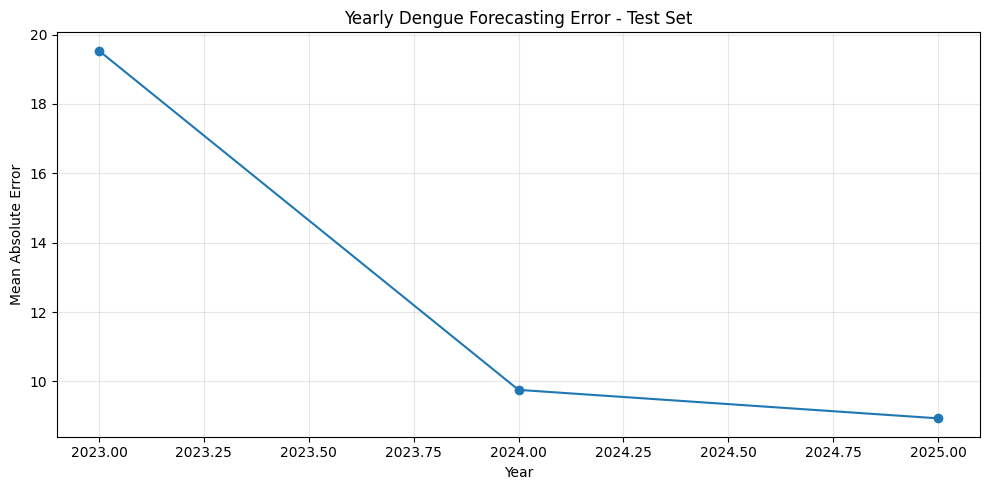

In [54]:
# CELL 17.3: YEARLY MAE

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_error_summary["target_year"],
    yearly_error_summary["MAE"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Mean Absolute Error")
plt.title("Yearly Dengue Forecasting Error - Test Set")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
# CELL 17.4: MONTHLY ERROR ANALYSIS

monthly_error_summary = (
    error_df.groupby("target_month")
    .agg(
        Observations=("actual_dengue_cases", "count"),
        Actual_Mean=("actual_dengue_cases", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=("squared_error",
              lambda x: np.sqrt(x.mean()))
    )
    .reset_index()
)

display(monthly_error_summary)

,target_month,Observations,Actual_Mean,MAE,RMSE
0,1,200,73.440000,18.587073,41.534654
1,2,275,48.029091,12.038264,21.036867
2,3,350,35.811429,9.920085,18.449719
3,4,325,39.600000,11.494191,21.844577
4,5,325,49.286154,13.048321,29.825595
5,6,325,53.716923,12.090663,29.945240
6,7,325,50.175385,11.663284,24.263929
7,8,350,35.017143,8.855629,15.431760
8,9,325,25.735385,7.131690,11.644115
9,10,300,31.550000,10.474967,25.454593


In [56]:
# CELL 17.5: SAVE TEMPORAL ERROR RESULTS

TEMPORAL_OUTPUT_DIR = (
    PROJECT_ROOT / "outputs" / "model_comparison"
)

yearly_error_summary.to_csv(
    TEMPORAL_OUTPUT_DIR / "yearly_forecasting_error.csv",
    index=False
)

monthly_error_summary.to_csv(
    TEMPORAL_OUTPUT_DIR / "monthly_forecasting_error.csv",
    index=False
)

print("Temporal error analysis saved successfully.")

Temporal error analysis saved successfully.


In [57]:
# CELL 18.1: CONSOLIDATED MODEL EVALUATION

forecasting_evaluation = pd.DataFrame([
    {
        "Evaluation": "Overall test performance",
        "MAE": final_test_mae,
        "RMSE": final_test_rmse,
        "R2": final_test_r2
    },
    {
        "Evaluation": "Low dengue cases",
        "MAE": case_level_summary.loc[
            case_level_summary["case_level"] == "Low",
            "MAE"
        ].iloc[0],
        "RMSE": case_level_summary.loc[
            case_level_summary["case_level"] == "Low",
            "RMSE"
        ].iloc[0],
        "R2": np.nan
    },
    {
        "Evaluation": "Medium dengue cases",
        "MAE": case_level_summary.loc[
            case_level_summary["case_level"] == "Medium",
            "MAE"
        ].iloc[0],
        "RMSE": case_level_summary.loc[
            case_level_summary["case_level"] == "Medium",
            "RMSE"
        ].iloc[0],
        "R2": np.nan
    },
    {
        "Evaluation": "High dengue cases",
        "MAE": case_level_summary.loc[
            case_level_summary["case_level"] == "High",
            "MAE"
        ].iloc[0],
        "RMSE": case_level_summary.loc[
            case_level_summary["case_level"] == "High",
            "RMSE"
        ].iloc[0],
        "R2": np.nan
    }
])

display(forecasting_evaluation)

,Evaluation,MAE,RMSE,R2
0,Overall test performance,12.564265,29.904042,0.819327
1,Low dengue cases,6.593727,12.148437,NaN
2,Medium dengue cases,21.994499,33.512436,NaN
3,High dengue cases,75.707196,115.924091,NaN


In [58]:
# CELL 18.2: SAVE CONSOLIDATED EVALUATION

evaluation_path = (
    PROJECT_ROOT
    / "outputs"
    / "model_comparison"
    / "riskweave_forecasting_evaluation_summary.csv"
)

forecasting_evaluation.to_csv(
    evaluation_path,
    index=False
)

print("Forecasting evaluation summary saved:")
print(evaluation_path)

Forecasting evaluation summary saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\model_comparison\riskweave_forecasting_evaluation_summary.csv
